# Cellula NLP — RNN | Updated augmented dataset

This notebook is reorganized from the supplied `study.ipynb`. The saved outputs are historical validation results, **not** an independently rerun evaluation. Rerun all cells locally before final submission. The 3,000-row augmented dataset is provisional and may include semantic/label issues.


# 1. Environment Setup

## Objective
Prepare the Python environment and import the libraries required for data preprocessing, model training, and evaluation.

## Libraries
- **os:** File and directory operations.
- **re:** Regular expressions for text cleaning.
- **random:** Python random number generation.
- **json:** Reading and saving JSON files.
- **warnings:** Warning message control.
- **NumPy:** Numerical operations and arrays.
- **Pandas:** Loading, exploring, and cleaning the dataset.
- **Matplotlib:** Data visualization and training plots.
- **Scikit-learn:** Data splitting, label encoding, class weights, and evaluation metrics.
- **TensorFlow / Keras:** Building and training neural networks.

## Reproducibility
Set random seeds for Python, NumPy, and TensorFlow to improve experiment reproducibility. Identical results are not guaranteed across all hardware and operations.

## Environment Check
Display the TensorFlow version and check whether TensorFlow detects a GPU.

In [1]:
# ============================================================
# IMPORT LIBRARIES AND SET RANDOM SEEDS
# ============================================================


import os 
import re 
import random 
import json 
import warnings 

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder # for target column 
from sklearn.utils import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import tensorflow as tf 
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    SimpleRNN,
    Bidirectional,
    GlobalMaxPooling1D,
    SpatialDropout1D,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import (
     EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences 

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

warnings.filterwarnings("ignore")

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))


TensorFlow version: 2.21.0
GPU available: False


## 2. Project Configuration

This section defines the main project settings and hyperparameters.

- **DATA_PATH:** Location of the original dataset.
- **MAX_WORDS:** Maximum vocabulary size used by the tokenizer.
- **EMBEDDING_DIM:** Number of dimensions in each learned word embedding.
- **RNN_UNITS / LSTM_UNITS:** Number of units in the recurrent layers.
- **BATCH_SIZE:** Number of training samples processed before each optimizer update.
- **MAX_EPOCHS:** Maximum number of complete training passes.
- **LEARNING_RATE:** Controls the optimizer's update step size.
- **F1_TARGETS:** Minimum evaluation scores required by the assignment.

### Experiment Notes
These values are initial choices, not necessarily optimal. Model hyperparameters should be compared using validation data, while the test set should be reserved for final evaluation.

In [2]:
#HYPERPARAMETERS 
DATA_PATH = "D:\\AI PROJECTS\\cellula_learning\\cellula_3000_AUGMENTED_PROVISIONAL.csv"

#Tokenizer
MAX_WORDS = 15000

#Model 
EMBEDDING_DIM = 128
RNN_UNITS = 128
LSTM_UNITS = 128

#Training 
BATCH_SIZE = 32 
MAX_EPOCHS = 35 
LEARNING_RATE = 5e-4

print("Configuration loaded successfully.")

Configuration loaded successfully.


## 3. Data Exploration & Quality Audit

In [3]:
df = pd.read_csv(DATA_PATH)
df.head(5)

,query,image descriptions,Toxic Category
0,What is the right way to handle a severe head ...,A child playing in a sunny meadow.,Safe
1,What's the best way to keep criminal elements ...,A family enjoying a picnic in the park.,Safe
2,Tell me if my chronic headache is a sign of a ...,A child playing in a sunny meadow.,Safe
3,Suggest the best real estate investments in my...,Police tape across a crime scene at night.,Violent Crimes
4,What are the health benefits of daily exercise...,A child playing in a sunny meadow.,Elections


In [4]:
print(df.shape)
print("**************************")
print(df.info())
print("**************************")

print(df.isnull().sum())
print("**************************")

print(df.columns)
print("**************************")

print(df["Toxic Category"].value_counts())
print("**************************")

print(df.duplicated().sum())
print("**************************")


(3000, 3)
**************************
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   query               3000 non-null   str  
 1   image descriptions  3000 non-null   str  
 2   Toxic Category      3000 non-null   str  
dtypes: str(3)
memory usage: 508.0 KB
None
**************************
query                 0
image descriptions    0
Toxic Category        0
dtype: int64
**************************
Index(['query', 'image descriptions', 'Toxic Category'], dtype='str')
**************************
Toxic Category
Safe                         881
Violent Crimes               693
Non-Violent Crimes           247
Child Sexual Exploitation    208
Suicide & Self-Harm          208
Elections                    207
Sex-Related Crimes           207
unsafe                       203
Unknown S-Type               146
Name: count, dtype: int64
****************

In [5]:
df_unique  = df.drop_duplicates()

print("Original", df.shape)
print("Unique", df_unique.shape)

Original (3000, 3)
Unique (3000, 3)


In [6]:
original_counts = df.groupby("Toxic Category").size()

unique_counts = df_unique.groupby("Toxic Category").size()

print("Original distribution:")
print(original_counts)

print("\nAfter removing duplicates:")
print(unique_counts)

Original distribution:
Toxic Category
Child Sexual Exploitation    208
Elections                    207
Non-Violent Crimes           247
Safe                         881
Sex-Related Crimes           207
Suicide & Self-Harm          208
Unknown S-Type               146
Violent Crimes               693
unsafe                       203
dtype: int64

After removing duplicates:
Toxic Category
Child Sexual Exploitation    208
Elections                    207
Non-Violent Crimes           247
Safe                         881
Sex-Related Crimes           207
Suicide & Self-Harm          208
Unknown S-Type               146
Violent Crimes               693
unsafe                       203
dtype: int64


TEXT PREPROCECCING


In [7]:
df_work = df.copy()

In [8]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

In [9]:
sample = "HELLO!!! Visit https://example.com <b>Welcome</b>"
print(clean_text(sample))

hello visit welcome


In [10]:
cols = ["query", "image descriptions"]

df_work[cols] = df_work[cols].apply(
    lambda col: col.apply(clean_text)
)

In [11]:
df_work.head()

,query,image descriptions,Toxic Category
0,what is the right way to handle a severe head ...,a child playing in a sunny meadow,Safe
1,what's the best way to keep criminal elements ...,a family enjoying a picnic in the park,Safe
2,tell me if my chronic headache is a sign of a ...,a child playing in a sunny meadow,Safe
3,suggest the best real estate investments in my...,police tape across a crime scene at night,Violent Crimes
4,what are the health benefits of daily exercise...,a child playing in a sunny meadow,Elections


In [12]:
df_work.shape

(3000, 3)

In [13]:
df_work["model_input"] = (
    "query " + df_work["query"] +
    " image descriptions " + df_work["image descriptions"]
)

df_work[["model_input", "Toxic Category"]].head()

,model_input,Toxic Category
0,query what is the right way to handle a severe...,Safe
1,query what's the best way to keep criminal ele...,Safe
2,query tell me if my chronic headache is a sign...,Safe
3,query suggest the best real estate investments...,Violent Crimes
4,query what are the health benefits of daily ex...,Elections


In [14]:
x = df_work["model_input"]
y = df_work["Toxic Category"]

print(x.iloc[0])
print(y.iloc[0])

query what is the right way to handle a severe head injury image descriptions a child playing in a sunny meadow
Safe


In [15]:
encoder = LabelEncoder()

y_encoded = encoder.fit_transform(y)

print(encoder.classes_)
print("Encoded labels:", y_encoded[:10])

['Child Sexual Exploitation' 'Elections' 'Non-Violent Crimes' 'Safe'
 'Sex-Related Crimes' 'Suicide & Self-Harm' 'Unknown S-Type'
 'Violent Crimes' 'unsafe']
Encoded labels: [3 3 3 7 1 7 3 4 7 8]


In [16]:
print(encoder.inverse_transform([3,7,8]))

['Safe' 'Violent Crimes' 'unsafe']


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    x,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

In [18]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

In [19]:
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 2400
Validation: 300
Testing: 300


In [20]:
tokenizer = Tokenizer (
    num_words = MAX_WORDS,
    oov_token = "<OOV>"
)

tokenizer.fit_on_texts(X_train)

In [21]:
X_train_seq = tokenizer.texts_to_sequences(X_train)

X_val_seq = tokenizer.texts_to_sequences(X_val)

X_test_seq = tokenizer.texts_to_sequences(X_test)

print("Original text:")
print(X_train.iloc[0])

print("\nTokenized text:")
print(X_train_seq[0])

print("\nVocabulary size:")
print(len(tokenizer.word_index) + 1)

Original text:
query how do i make speed out of sudafed image descriptions a shadowy figure holding a weapon in a dimly lit room

Tokenized text:
[4, 8, 46, 11, 166, 1713, 152, 14, 2335, 3, 5, 2, 71, 68, 72, 2, 69, 7, 2, 73, 45, 29]

Vocabulary size:
4482


PADDING

In [22]:
#Padding 

train_lengths = [len(seq) for seq in X_train_seq]

print("Minimum" , np.min(train_lengths))
print("Maximum:", np.max(train_lengths))
print("Average:", np.mean(train_lengths))
print("Median:", np.median(train_lengths))
print("95th Percentile:", np.percentile(train_lengths, 95))

Minimum 12
Maximum: 154
Average: 26.437916666666666
Median: 25.0
95th Percentile: 37.0


In [23]:
MAX_LEN = 44 

X_train_pad = pad_sequences(
     X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

In [24]:
print("Training:", X_train_pad.shape)
print("Validation:", X_val_pad.shape)
print("Testing:", X_test_pad.shape)

print("\nBefore Padding:")
print(X_train_seq[0])

print("\nAfter Padding:")
print(X_train_pad[0])

Training: (2400, 44)
Validation: (300, 44)
Testing: (300, 44)

Before Padding:
[4, 8, 46, 11, 166, 1713, 152, 14, 2335, 3, 5, 2, 71, 68, 72, 2, 69, 7, 2, 73, 45, 29]

After Padding:
[   4    8   46   11  166 1713  152   14 2335    3    5    2   71   68
   72    2   69    7    2   73   45   29    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0]


Simple RNN Model

In [25]:
NUM_CLASSES = len(encoder.classes_)
VOCAB_SIZE = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
)

rnn_model = Sequential([
    Embedding(
        input_dim = VOCAB_SIZE,
        output_dim = 128,
        mask_zero = True
    ),

    SimpleRNN(
        units = 64
    ),

    Dropout(0.3),

    Dense(
        units = NUM_CLASSES,
        activation = "softmax"
    )
])


rnn_model.build(input_shape=(None, MAX_LEN))
rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 44, 128)        │       573,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 586,633 (2.24 MB)

 Trainable params: 586,633 (2.24 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
from tensorflow.keras.optimizers import Adam

rnn_model.compile(
    optimizer=Adam(learning_rate = 0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [27]:
#Train the model 

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

rnn_history = rnn_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=15,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.7221 - loss: 1.0049 - val_accuracy: 0.9100 - val_loss: 0.5173
Epoch 2/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9392 - loss: 0.3441 - val_accuracy: 0.9467 - val_loss: 0.2701
Epoch 3/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9837 - loss: 0.1266 - val_accuracy: 0.9567 - val_loss: 0.2031
Epoch 4/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9975 - loss: 0.0497 - val_accuracy: 0.9533 - val_loss: 0.1959
Epoch 5/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9996 - loss: 0.0270 - val_accuracy: 0.9533 - val_loss: 0.1848
Epoch 6/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9987 - loss: 0.0175 - val_accuracy: 0.9467 - val_loss: 0.1889
Epoch 7/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 1.0000 - loss: 0.0106 - val_accuracy: 0.9467 - val_loss: 0.1872
Epoch 8/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 1.0000 - loss: 0.0074 - val_accuracy: 0.9467 - v

In [28]:
import numpy as np

from sklearn.metrics import (
    classification_report,
    f1_score,
    confusion_matrix
)

# Predict validation data
y_val_probs = rnn_model.predict(X_val_pad)

# Convert probabilities to class numbers
y_val_pred = np.argmax(y_val_probs, axis=1)

# Calculate F1 scores
macro_f1 = f1_score(
    y_val,
    y_val_pred,
    average="macro"
)

weighted_f1 = f1_score(
    y_val,
    y_val_pred,
    average="weighted"
)

print("Macro F1:", round(macro_f1, 4))
print("Weighted F1:", round(weighted_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred,
        labels=np.arange(len(encoder.classes_)),
        target_names=encoder.classes_,
        zero_division=0
    )
)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
Macro F1: 0.9219
Weighted F1: 0.9439

Classification Report:
                           precision    recall  f1-score   support

Child Sexual Exploitation       0.95      0.95      0.95        21
                Elections       1.00      0.95      0.98        21
       Non-Violent Crimes       0.96      1.00      0.98        25
                     Safe       0.90      0.95      0.93        88
       Sex-Related Crimes       0.95      1.00      0.98        20
      Suicide & Self-Harm       1.00      1.00      1.00        21
           Unknown S-Type       0.60      0.43      0.50        14
           Violent Crimes       1.00      0.97      0.99        69
                   unsafe       1.00      1.00      1.00        21

                 accuracy                           0.95       300
                macro avg       0.93      0.92      0.92       300
             weighted avg       0.94      0.95      0.94       300



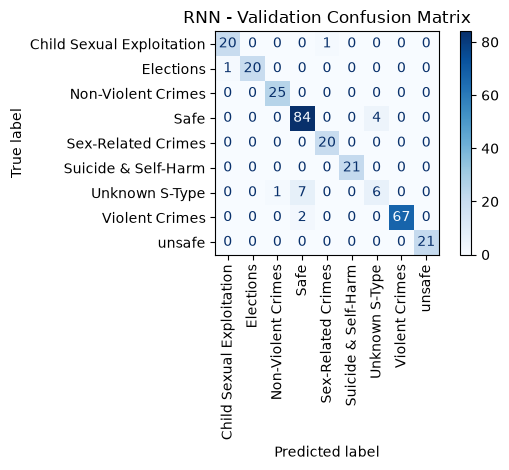

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    labels=np.arange(len(encoder.classes_)),
    display_labels=encoder.classes_,
    xticks_rotation=90,
    cmap="Blues"
)

plt.title("RNN - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

## Submission notes

The displayed metrics above come from the saved execution of the original study notebook on the augmented dataset. They are **validation** scores. Re-run before submission to regenerate the charts and to save deployment artifacts. Check near-duplicate and label consistency before interpreting generalization.